In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
# Project directory
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

# Dataset path
DATA_FILE = BASE_DIR / "data" / "sales_data_clean.csv"

# Load dataset
df = pd.read_csv(
    DATA_FILE,
    parse_dates=["OrderDate"]
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 13)


In [3]:
df.head()

,OrderID,OrderDate,CustomerID,Product,Category,Quantity,UnitPrice,Revenue,Region,Status,Year,Month,YearMonth
0,1001,2026-10-17,C0063,Mouse,Accessories,1,20.97,20.97,South,Completed,2026,10,2026-10
1,1002,2025-04-15,C0009,Pen,Stationery,1,2.04,2.04,North,Completed,2025,4,2025-04
2,1003,2025-08-27,C0051,Pen,Stationery,5,1.81,9.05,West,Completed,2025,8,2025-08
3,1004,2026-08-27,C0041,Headphones,Electronics,1,105.18,105.18,West,Completed,2026,8,2026-08
4,1005,2025-06-09,C0098,Monitor,Electronics,3,184.09,552.27,North,Completed,2025,6,2025-06


In [4]:
# Filter completed orders
completed_df = df[df["Status"] == "Completed"].copy()

print("Total Orders:", len(df))
print("Completed Orders:", len(completed_df))
print("Pending Orders:", (df["Status"] == "Pending").sum())
print("Cancelled Orders:", (df["Status"] == "Cancelled").sum())

Total Orders: 1000
Completed Orders: 737
Pending Orders: 151
Cancelled Orders: 112


In [5]:
# Calculate total revenue
total_revenue = completed_df["Revenue"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 315950.93


In [6]:
total_orders = len(completed_df)

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else 0
)

print("Completed Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))

Completed Orders: 737
Average Order Value: 428.7


In [7]:
top_products = (
    completed_df
    .groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(top_products)

Product
Laptop        137524.55
Desk           46887.34
Monitor        42414.74
Chair          36727.67
Headphones     22592.26
Webcam         13352.95
Keyboard       10158.51
Mouse           4593.20
Notebook        1162.76
Pen              536.95
Name: Revenue, dtype: float64


In [8]:
top_5_products = top_products.head(5)

print(top_5_products)

Product
Laptop        137524.55
Desk           46887.34
Monitor        42414.74
Chair          36727.67
Headphones     22592.26
Name: Revenue, dtype: float64


In [9]:
regional_sales = (
    completed_df
    .groupby("Region")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(regional_sales)

Region
South    87165.78
North    82469.96
West     74594.45
East     71720.74
Name: Revenue, dtype: float64


In [10]:
regional_percentage = (
    regional_sales / total_revenue * 100
)

print(regional_percentage.round(2))

Region
South    27.59
North    26.10
West     23.61
East     22.70
Name: Revenue, dtype: float64


In [11]:
monthly_sales = (
    completed_df
    .groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

print(monthly_sales)

YearMonth
2025-01     8385.46
2025-02    16831.91
2025-03    20836.53
2025-04    10298.90
2025-05    11138.36
2025-06    16324.07
2025-07    11911.51
2025-08    10532.76
2025-09    15267.42
2025-10    15138.65
2025-11    20568.39
2025-12    16495.45
2026-01    13255.76
2026-02    13842.69
2026-03    11569.93
2026-04    15251.55
2026-05     9157.02
2026-06    11874.70
2026-07    20605.47
2026-08    18194.61
2026-09    17432.64
2026-10    11037.15
Name: Revenue, dtype: float64


In [12]:
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

print("Best Month:", best_month)
print("Revenue:", round(best_month_revenue, 2))

Best Month: 2025-03
Revenue: 20836.53


In [13]:
weak_products = (
    completed_df
    .groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=True)
)

print("Three Weakest Products:")
print(weak_products.head(3))

Three Weakest Products:
Product
Pen          536.95
Notebook    1162.76
Mouse       4593.20
Name: Revenue, dtype: float64


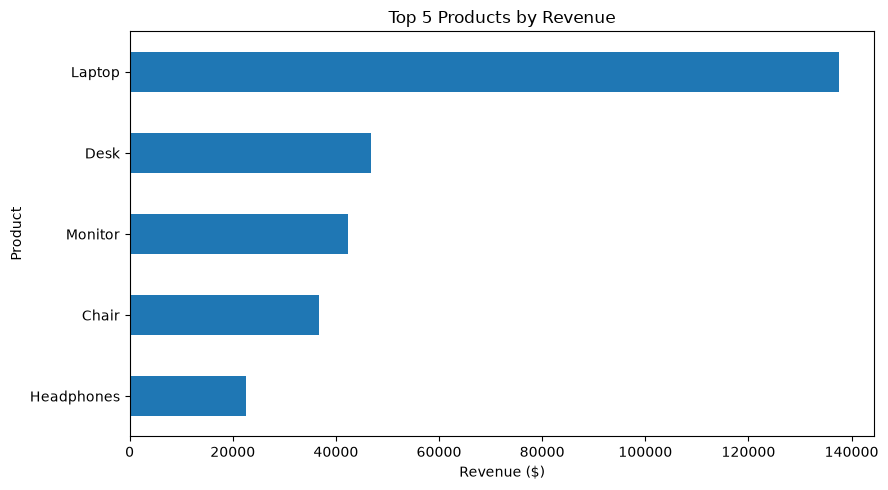

In [14]:
# Top 5 Products by Revenue

top_5_products.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 5 Products by Revenue"
)

plt.xlabel("Revenue ($)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

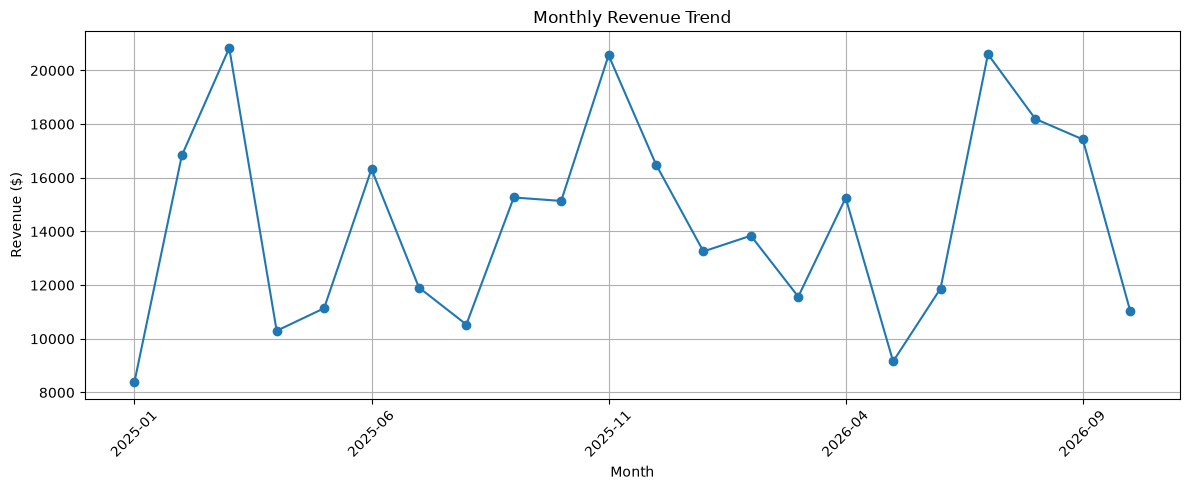

In [15]:

# Monthly Revenue Trend

monthly_revenue = completed_df.groupby("YearMonth")["Revenue"].sum()

monthly_revenue.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()


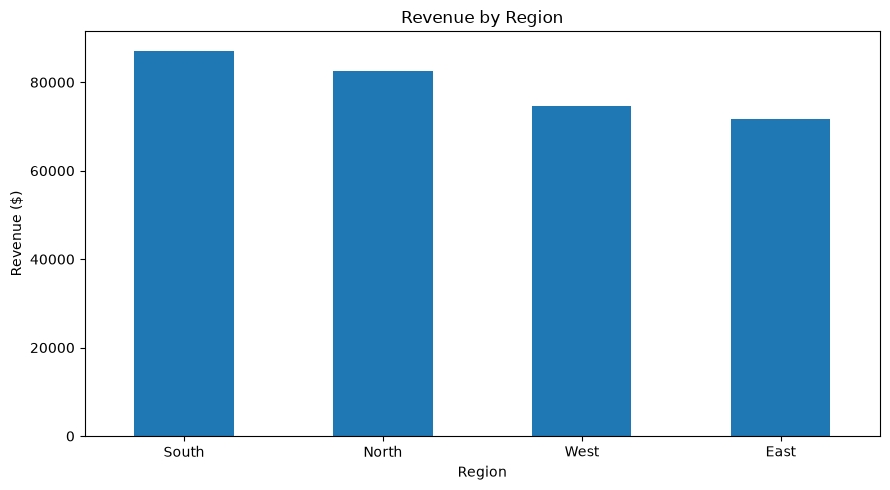

In [16]:

# Revenue by Region

revenue_by_region = completed_df.groupby("Region")["Revenue"].sum()

revenue_by_region = revenue_by_region.sort_values(ascending=False)

revenue_by_region.plot(
    kind="bar",
    figsize=(9, 5),
    title="Revenue by Region"
)

plt.xlabel("Region")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


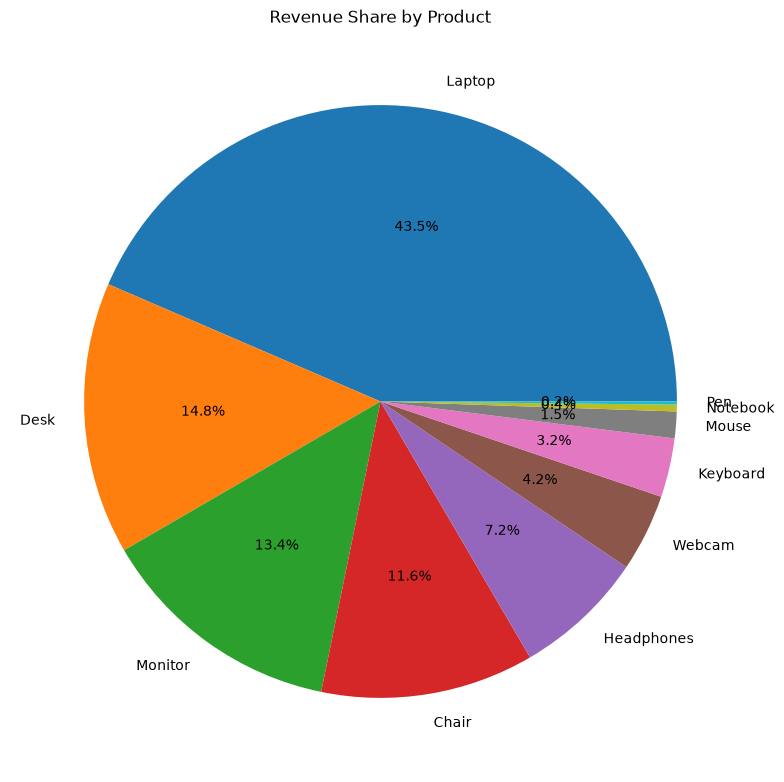

In [17]:

# Revenue Share by Product

product_revenue = completed_df.groupby("Product")["Revenue"].sum()

product_share = (product_revenue / product_revenue.sum()) * 100

product_share = product_share.sort_values(ascending=False)

product_share.plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    title="Revenue Share by Product"
)

plt.ylabel("")
plt.tight_layout()
plt.show()


In [18]:

# Export Business Analysis Results

import os

os.makedirs("output", exist_ok=True)

revenue_by_region.to_csv("output/revenue_by_region.csv")

product_share.to_csv("output/product_revenue_share.csv")

monthly_revenue.to_csv("output/monthly_revenue.csv")

top_5_products.to_csv("output/top_5_products.csv")

print("Business analysis results exported successfully.")


Business analysis results exported successfully.


In [19]:

# Business KPIs

total_revenue = completed_df["Revenue"].sum()

total_orders = len(df)

completed_orders = len(completed_df)

average_order_value = completed_df["Revenue"].mean()

completion_rate = (completed_orders / total_orders) * 100

cancellation_rate = (
    len(df[df["Status"] == "Cancelled"]) / total_orders
) * 100

print("===== BUSINESS KPIs =====")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Completed Orders: {completed_orders}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Completion Rate: {completion_rate:.2f}%")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")


===== BUSINESS KPIs =====
Total Revenue: $315,950.93
Total Orders: 1000
Completed Orders: 737
Average Order Value: $428.70
Completion Rate: 73.70%
Cancellation Rate: 11.20%


In [20]:

# Business Insights

best_product = product_revenue.idxmax()
best_product_revenue = product_revenue.max()

best_region = revenue_by_region.idxmax()
best_region_revenue = revenue_by_region.max()

best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()

print("===== BUSINESS INSIGHTS =====")

print(
    f"Top Product: {best_product} "
    f"with revenue of ${best_product_revenue:,.2f}"
)

print(
    f"Top Region: {best_region} "
    f"with revenue of ${best_region_revenue:,.2f}"
)

print(
    f"Best Sales Month: {best_month} "
    f"with revenue of ${best_month_revenue:,.2f}"
)


===== BUSINESS INSIGHTS =====
Top Product: Laptop with revenue of $137,524.55
Top Region: South with revenue of $87,165.78
Best Sales Month: 2025-03 with revenue of $20,836.53


In [21]:

# Generate Business Insights Report

report = f"""
BUSINESS INSIGHTS REPORT
========================

BUSINESS KPIs

Total Revenue: ${total_revenue:,.2f}
Total Orders: {total_orders}
Completed Orders: {completed_orders}
Average Order Value: ${average_order_value:,.2f}
Completion Rate: {completion_rate:.2f}%
Cancellation Rate: {cancellation_rate:.2f}%

BUSINESS INSIGHTS

Top Product: {best_product}
Product Revenue: ${best_product_revenue:,.2f}

Top Region: {best_region}
Region Revenue: ${best_region_revenue:,.2f}

Best Sales Month: {best_month}
Monthly Revenue: ${best_month_revenue:,.2f}
"""

with open("output/business_insights_report.txt", "w") as file:
    file.write(report)

print("Business Insights Report created successfully!")


Business Insights Report created successfully!
